In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.optimize import curve_fit
from scipy.stats import linregress
import pandas as pd

In [10]:
#standard curves

def std_curve(filepath, split1=None, split2=None):
    df = pd.read_csv(filepath, sep='\t', decimal=',')
    df['std'] = df['std'] - df['std'].iloc[0]

    if split1 is None: # No splitting: fit the entire curve
        df1 = df.copy()
        result = linregress(df1['conc'], df1['std'])
        a1 = result.slope
        b1 = result.intercept
        r1 = result.rvalue
        # Force intercept to 0
        x = df1['conc']
        y = df1['std']
        a1 = np.sum(x * y) / np.sum(x * x)
        b1 = 0
        df2, a2, b2, r2 = df1, a1, b1, r1
        df3, a3, b3, r3 = df1, a1, b1, r1
        threshold1 = 0
        threshold2 = 0

    else:
        # First segment
        df1 = df.iloc[:split1 + 1].copy()
        x = df1['conc']
        y = df1['std']
        a1 = np.sum(x * y) / np.sum(x * x)
        b1 = 0
        result = linregress(df1['conc'], df1['std'])
        r1 = result.rvalue
        threshold1 = df.iloc[split1]['std']

        # Only one split
        if split2 is None:
            df2 = df.iloc[split1:].copy()
            result = linregress(df2['conc'], df2['std'])
            a2 = result.slope
            b2 = result.intercept
            r2 = result.rvalue
            df3, a3, b3, r3 = df2, a2, b2, r2
            threshold2 = 0

        # Two splits
        else:
            # Second segment
            df2 = df.iloc[split1:split2 + 1].copy()
            result = linregress(df2['conc'], df2['std'])
            a2 = result.slope
            b2 = result.intercept
            r2 = result.rvalue
            threshold2 = df.iloc[split2]['std']
            # Third segment
            df3 = df.iloc[split2:].copy()
            result = linregress(df3['conc'], df3['std'])
            a3 = result.slope
            b3 = result.intercept
            r3 = result.rvalue

    return (
        df1, (a1, b1, r1),
        df2, (a2, b2, r2),
        df3, (a3, b3, r3),
        threshold1, threshold2
    )

def plot_std_curve(filepath, title, ax, split1=None, split2=None):
    df1, s1, df2, s2, df3, s3, threshold1, threshold2 = std_curve(filepath, split1, split2)

    # Data
    ax.plot(df1['conc'], df1['std'], 'ro')
    ax.plot(df2['conc'], df2['std'], 'ro')
    ax.plot(df3['conc'], df3['std'], 'ro')

    # Fits
    ax.plot(df1['conc'], s1[0] * df1['conc'] + s1[1], 'k')
    ax.plot(df2['conc'], s2[0] * df2['conc'] + s2[1], 'k')
    ax.plot(df3['conc'], s3[0] * df3['conc'] + s3[1], 'k')

    ax.set_title(title)
    ax.set_xlabel('Concentration (nM)')
    ax.set_ylabel('FI')

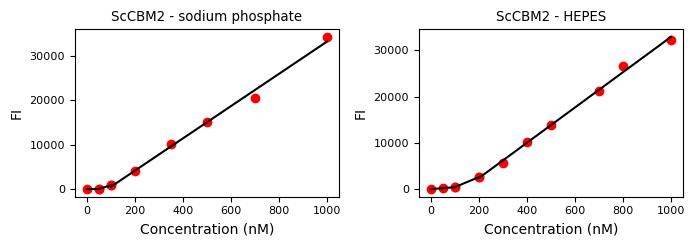

In [77]:
fig, axs = plt.subplots(1, 2, figsize=(7, 2.5))
plot_std_curve("data/PET_ScCBM2_std_60.txt", "ScCBM2 - sodium phosphate", axs[0], split1=1, split2=2)
plot_std_curve("data/PET_ScCBM2_std_60_HEPES.txt", "ScCBM2 - HEPES", axs[1], split1=2, split2=3)
plt.tight_layout()



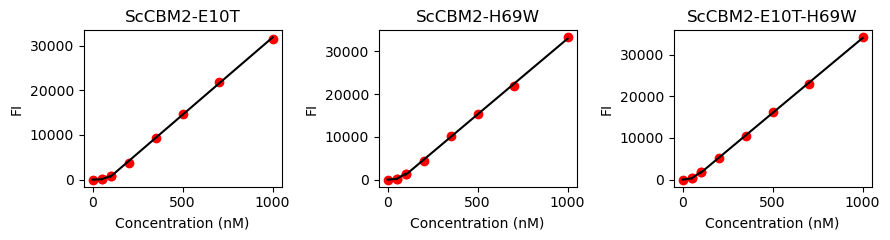

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.5))
plot_std_curve("data/PET_ScCBM2-E12T_std_60.txt", "ScCBM2-E10T", axs[0], split1=1, split2=2)
plot_std_curve("data/PET_ScCBM2-H71W_std_60.txt", "ScCBM2-H69W", axs[1], split1=1, split2=2)
plot_std_curve("data/PET_ScCBM2-E12T-H71W_std_60.txt", "ScCBM2-E10T-H69W", axs[2], split1=1, split2=2)
plt.tight_layout()

In [110]:
# Assay

def calculate_binding_data(filepath_assay, filepath_std, split1=None, split2=None, lp=None):
    # Load standard curve
    std1, s1, std2, s2, std3, s3, threshold1, threshold2 = std_curve(filepath_std, split1, split2)
    # Load assay data
    df = pd.read_csv(filepath_assay, sep='\t', decimal=',')

    # Zero with blank
    blank = df.drop(columns='conc').iloc[0].mean()
    df[df.columns.drop('conc')] -= blank
    # Correct negative values
    df = df.clip(lower=0)
    # Find where to split assay data to use accurate part of std curve
    avg = df.drop(columns='conc').mean(axis=1)
    index1 = avg[avg > threshold1].index[0]

    if split2 is not None:
        index2 = avg[avg > threshold2].index[0]
    else:
        index2 = len(df)

    # Split assay data
    df1 = df.iloc[:index1].copy()
    df2 = df.iloc[index1:index2].copy()
    df3 = df.iloc[index2:].copy()

    # Calculate Pfree for first region
    cols = df1.columns.drop('conc')
    new_cols = [f"F{i+1}" for i in range(len(cols))]
    a = s1[0]
    b = s1[1]
    df1[new_cols] = (df1[cols] - b) / a

    # Calculate Pfree for second region
    cols = df2.columns.drop('conc')
    new_cols = [f"F{i+1}" for i in range(len(cols))]
    a = s2[0]
    b = s2[1]
    df2[new_cols] = (df2[cols] - b) / a

    # Calculate Pfree for third region
    cols = df3.columns.drop('conc')
    new_cols = [f"F{i+1}" for i in range(len(cols))]
    a = s3[0]
    b = s3[1]
    df3[new_cols] = (df3[cols] - b) / a

    # Combine dataframes
    df = pd.concat([df1, df2, df3])

    # Calculate Pbound
    f_cols = df.filter(like='F').columns
    for i, col in enumerate(f_cols):
        df[f"b{i+1}"] = df['conc'] - df[col]

    # Calculate Pbound in nmol/cm² PET
    vol = 300 * 10**(-6)  # L
    area = 0.64  # cm²
    b_cols = df.filter(like='b').columns
    df[b_cols] = df[b_cols] * vol / area

    # Calculate averages
    f_cols = df.filter(like='F').columns
    df['F_avg'] = df[f_cols].mean(axis=1)
    df['F_std'] = df[f_cols].std(axis=1)
    b_cols = df.filter(like='b').columns
    df['B_avg'] = df[b_cols].mean(axis=1)
    df['B_std'] = df[b_cols].std(axis=1)

    # Remove last point
    if lp is not None:
        df = df.iloc[:-1]

    return df, df['F_avg'], df['B_avg'], df['B_std']

def calc_bound_P(P,Kd,Bmax): 
    return Bmax*P/(Kd+P)

def plot_data(filepath_assay, filepath_std, ax, label, col, split1=None, split2=None, lp=None):
    df, Pfree, Pbound, Pbound_err = calculate_binding_data(filepath_assay, filepath_std, split1, split2, lp)
    
    #Fit
    popt, pcov = curve_fit(calc_bound_P, Pfree, Pbound)
    error = np.sqrt(np.diag(pcov))
    
    #Plot
    x_values = np.linspace(0, 1000, 100)
    ax.plot(x_values, calc_bound_P(x_values, popt[0], popt[1]), color = f"{col}", linestyle = '--', linewidth = 0.9)
    
    ax.errorbar(Pfree, Pbound, 
                 yerr=Pbound_err, 
                 fmt='o', 
                 markersize=3,
                 elinewidth = 0.5,
                 capsize = 2,
                 color=f"{col}", 
                 label=f"{label}")
    
    #Print Kd/Bmax 
    print(f"{label}"+' on PET:')
    print('Kd = ' + str(popt[0]) + u"\u00B1" + str(error[0]) + "nM")
    print('Bmax = ' + str(popt[1]) + u"\u00B1" + str(error[1]) + "nmol/cm^2")
    
    #Calculate Kr
    Kr = popt[1]/popt[0]
    Kr_err = Kr * np.sqrt((error[0] / popt[0])**2 + (error[1] / popt[1])**2)
    print('Kr = ' + f"{Kr:.{5}f}" + u"\u00B1" + f"{Kr_err:.{5}f}")

GFP-$\mathit{Sc}$CBM2, HEPES on PET:
Kd = 18063386394.08654±2.269389766159672e+17nM
Bmax = 566742.2855469573±7120254403555.648nmol/cm^2
Kr = 0.00003±557.45697
GFP-$\mathit{Sc}$CBM2, Phosphate on PET:
Kd = 7.292435837455907±5.758869847604783nM
Bmax = 0.023119982803878017±0.001790352972657979nmol/cm^2
Kr = 0.00317±0.00252


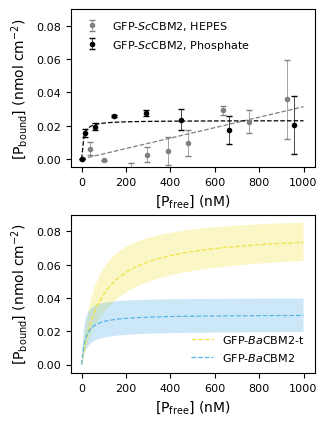

In [111]:
width_mm = 80
width_in = width_mm / 25.4 
height_in = width_in * 1.5

plt.rcParams.update({
    "font.size": 8,        # base font size
    "axes.labelsize": 10,   # axis labels
    "xtick.labelsize": 8,  # x tick labels
    "ytick.labelsize": 8,  # y tick labels
    "legend.fontsize": 8,  # legend
})

fig, ax = plt.subplots(2, 1, sharey=True, figsize=(width_in, height_in))
plt.subplots_adjust(hspace=0.3)

plot_data("data/PET_ScCBM2_assay_60_HEPES.txt", "data/PET_ScCBM2_std_60_HEPES.txt", ax[0], r'GFP-$\mathit{Sc}$CBM2, HEPES', "gray", split1=2, split2=3)
plot_data("data/PET_ScCBM2_assay_60.txt", "data/PET_ScCBM2_std_60.txt", ax[0], r'GFP-$\mathit{Sc}$CBM2, Phosphate', "k", split1=1, split2=2)


# BaCBM2 data from Rennison et al. 10.1016/j.scitotenv.2023.161948
KdA = 89 #nM
BmaxA = 0.08 #nmol/cm^2
Kd_std = 34
Bmax_std = 0.01

x_values = np.linspace(0, 1000, 100)
y_upper = calc_bound_P(x_values, KdA - Kd_std, BmaxA + Bmax_std)
y_lower = calc_bound_P(x_values, KdA + Kd_std, BmaxA - Bmax_std)

ax[1].fill_between(x_values, y_lower, y_upper, alpha=0.3, color = "#F0E442",edgecolor='none')
ax[1].plot (x_values, calc_bound_P(x_values, KdA, BmaxA), color = "#F0E442", linestyle = '--', linewidth = 0.9, label = r'GFP-$\mathit{Ba}$CBM2-t')

KdA = 16 #nM
BmaxA = 0.03 #nmol/cm^2
Kd_std = 8
Bmax_std = 0.01

y_upper = calc_bound_P(x_values, KdA - Kd_std, BmaxA + Bmax_std)
y_lower = calc_bound_P(x_values, KdA + Kd_std, BmaxA - Bmax_std)

ax[1].fill_between(x_values, y_lower, y_upper, alpha=0.3, color = "#56B5E9",edgecolor='none')
ax[1].plot (x_values, calc_bound_P(x_values, KdA, BmaxA), color = "#56B5E9", linestyle = '--', linewidth = 0.9, label = r'GFP-$\mathit{Ba}$CBM2')


ax[0].set_xlabel('[P$_{\mathrm{free}}$] (nM)')
ax[1].set_xlabel('[P$_{\mathrm{free}}$] (nM)')
ax[0].set_ylabel('[P$_{\mathrm{bound}}$] (nmol cm$^{-2}$)')
ax[1].set_ylabel('[P$_{\mathrm{bound}}$] (nmol cm$^{-2}$)')
ax[0].set_ylim(-0.005, 0.09)
ax[1].legend(loc = 'lower right', markerfirst = True, frameon = False)
ax[0].legend(loc = 'upper left', markerfirst = True, frameon = False)

plt.savefig('plots/PET_binding.png', dpi = 600, bbox_inches='tight')
plt.savefig('plots/PET_binding.svg', bbox_inches='tight')

$\mathit{Sc}$CBM2, HEPES on PET:
Kd = 18063386394.08654±2.269389766159672e+17nM
Bmax = 566742.2855469573±7120254403555.648nmol/cm^2
Kr = 0.00003±557.45697
$\mathit{Sc}$CBM2, Phosphate on PET:
Kd = 7.292435837455907±5.758869847604783nM
Bmax = 0.023119982803878017±0.001790352972657979nmol/cm^2
Kr = 0.00317±0.00252


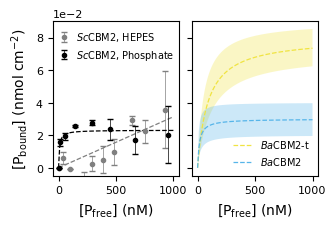

In [112]:
width_mm = 87
width_in = width_mm / 25.4 
height_in = 85*0.6/25.4

plt.rcParams.update({
    "font.size": 8,        # base font size
    "axes.labelsize": 10,   # axis labels
    "xtick.labelsize": 8,  # x tick labels
    "ytick.labelsize": 8,  # y tick labels
    "legend.fontsize": 7,  # legend
})

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(width_in, height_in))
plt.subplots_adjust(wspace=0.1)

plot_data("data/PET_ScCBM2_assay_60_HEPES.txt", "data/PET_ScCBM2_std_60_HEPES.txt", ax[0], r'$\mathit{Sc}$CBM2, HEPES', "gray", split1=2, split2=3)
plot_data("data/PET_ScCBM2_assay_60.txt", "data/PET_ScCBM2_std_60.txt", ax[0], r'$\mathit{Sc}$CBM2, Phosphate', "k", split1=1, split2=2)


# BaCBM2 data from Rennison et al. 10.1016/j.scitotenv.2023.161948
KdA = 89 #nM
BmaxA = 0.08 #nmol/cm^2
Kd_std = 34
Bmax_std = 0.01

x_values = np.linspace(0, 1000, 100)
y_upper = calc_bound_P(x_values, KdA - Kd_std, BmaxA + Bmax_std)
y_lower = calc_bound_P(x_values, KdA + Kd_std, BmaxA - Bmax_std)

ax[1].fill_between(x_values, y_lower, y_upper, alpha=0.3, color = "#F0E442",edgecolor='none')
ax[1].plot (x_values, calc_bound_P(x_values, KdA, BmaxA), color = "#F0E442", linestyle = '--', linewidth = 0.9, label = r'$\mathit{Ba}$CBM2-t')

KdA = 16 #nM
BmaxA = 0.03 #nmol/cm^2
Kd_std = 8
Bmax_std = 0.01

y_upper = calc_bound_P(x_values, KdA - Kd_std, BmaxA + Bmax_std)
y_lower = calc_bound_P(x_values, KdA + Kd_std, BmaxA - Bmax_std)

ax[1].fill_between(x_values, y_lower, y_upper, alpha=0.3, color = "#56B5E9",edgecolor='none')
ax[1].plot (x_values, calc_bound_P(x_values, KdA, BmaxA), color = "#56B5E9", linestyle = '--', linewidth = 0.9, label = r'$\mathit{Ba}$CBM2')


ax[0].set_xlabel('[P$_{\mathrm{free}}$] (nM)')
ax[1].set_xlabel('[P$_{\mathrm{free}}$] (nM)')
ax[0].set_ylabel('[P$_{\mathrm{bound}}$] (nmol cm$^{-2}$)')
ax[0].set_ylim(-0.005, 0.09)
ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax[1].legend(loc = 'lower right', markerfirst = True, frameon = False)
ax[0].legend(loc = 'upper left',bbox_to_anchor=(-0.055, 1), handletextpad=0.15, markerfirst = True, frameon = False)

plt.savefig('plots/PET_binding_compact.png', dpi = 600, bbox_inches='tight')
plt.savefig('plots/PET_binding_compact.svg', bbox_inches='tight')

wt on PET:
Kd = 7.292435837455907±5.758869847604783nM
Bmax = 0.023119982803878017±0.001790352972657979nmol/cm^2
Kr = 0.00317±0.00252
E10T on PET:
Kd = 85.18047479213007±52.37541038023219nM
Bmax = 0.02006214480663643±0.00336795227966143nmol/cm^2
Kr = 0.00024±0.00015
H69W on PET:
Kd = 23.059364888236594±11.30048389452104nM
Bmax = 0.01730036811248708±0.0013593940158735242nmol/cm^2
Kr = 0.00075±0.00037
E10T-H69W on PET:
Kd = 26.21120156025145±32.50407962766222nM
Bmax = 0.017430294302963417±0.003599611069634946nmol/cm^2
Kr = 0.00066±0.00084


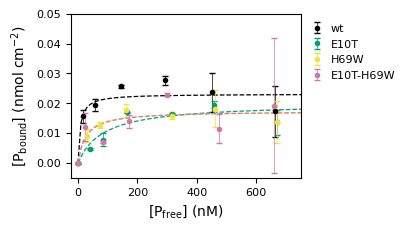

In [125]:
# ScCBM2 mutants on PET

width_mm = 80
width_in = width_mm / 25.4 
height_in = 85*0.7/25.4

plt.rcParams.update({
    "font.size": 8,        # base font size
    "axes.labelsize": 10,   # axis labels
    "xtick.labelsize": 8,  # x tick labels
    "ytick.labelsize": 8,  # y tick labels
    "legend.fontsize": 8,  # legend
})

fig, ax = plt.subplots(1, 1, figsize=(width_in, height_in))
plot_data("data/PET_ScCBM2_assay_60.txt", "data/PET_ScCBM2_std_60.txt", ax, 'wt', "k", split1=1, split2=2)
plot_data("data/PET_ScCBM2-E12T_assay_60.txt", "data/PET_ScCBM2-E12T_std_60.txt", ax, 'E10T', '#009E73', split1=1, split2=2, lp=1)
plot_data("data/PET_ScCBM2-H71W_assay_60.txt", "data/PET_ScCBM2-H71W_std_60.txt", ax, 'H69W', '#F0E442', split1=1, split2=2, lp=1)
plot_data("data/PET_ScCBM2-E12T-H71W_assay_60.txt", "data/PET_ScCBM2-E12T-H71W_std_60.txt", ax, 'E10T-H69W', '#CC79A7', split1=1, split2=2, lp=1)


ax.set_xlabel('[P$_{\mathrm{free}}$] (nM)')
ax.set_ylabel('[P$_{\mathrm{bound}}$] (nmol cm$^{-2}$)')
ax.set_xlim(-25,750)
ax.set_ylim(-0.005, 0.05)
plt.tight_layout()
plt.legend(loc='upper left', bbox_to_anchor=(0.98, 1),frameon = False, handletextpad=0.2)

plt.savefig('plots/ScCBM2_mut_PET.png', dpi = 600, bbox_inches = 'tight')
plt.savefig('plots/ScCBM2_mut_PET.svg')

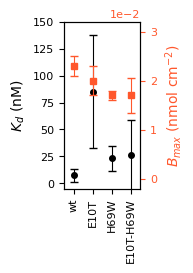

In [162]:
mutants = ['wt', 'E10T', 'H69W', 'E10T-H69W']
Kds = [7.29, 85.18, 23.06, 26.21]
Kd_errs = [5.76, 52.37, 11.30, 32.50]
Bmax = [0.023, 0.020, 0.017, 0.017]
Bmax_errs = [0.002, 0.003, 0.001, 0.0036]

Kr = [0.0032, 0.00024, 0.00075, 0.00066]
Kr_err = [0.0025, 0.00015, 0.00037, 0.00084]



width_mm = 25
width = width_mm / 25.4 
height = 55 / 25.4 

plt.rcParams.update({
    "font.size": 8,        # base font size
    "axes.labelsize": 10,   # axis labels
    "xtick.labelsize": 8,  # x tick labels
    "ytick.labelsize": 8,  # y tick labels
    "legend.fontsize": 8,  # legend
})

fig, ax = plt.subplots(1, 1, figsize=(width, height))
ax.errorbar(mutants, Kds, yerr = Kd_errs, fmt='o', markersize=4, elinewidth = 0.8, capsize = 3, color='k')
ax.tick_params(axis='y', labelcolor='k')
ax.set_ylabel('$K_d$ (nM)')
ax.tick_params(axis='x', labelrotation=90)
ax.set_ylim(-5,150)
ax.set_xlim(-0.5, 3.5)

color2 = '#ff572c'

ax2 = ax.twinx()
ax2.errorbar(mutants, Bmax, yerr = Bmax_errs, fmt='s', markersize=4, elinewidth = 0.8, capsize = 3, color=color2)
ax2.tick_params(axis='y', colors=color2)
ax2.set_ylabel('$B_{max}$ (nmol cm$^{-2}$)', color=color2)
ax2.set_ylim(-0.002,0.032)
ax2.yaxis.set_major_locator(MultipleLocator(0.01))
ax2.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.savefig('plots/ScCBM2_mut_PET_Kd_Bmax.svg',bbox_inches='tight')